In [1]:
import re
from collections.abc import Iterable
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from torch import nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset, random_split


### Dataset loading and validation

In [2]:
def load_directory(dataset_dir: str | Path) -> pd.DataFrame:
    """Load category-folder article files into a DataFrame."""
    root = Path(dataset_dir)
    if not root.is_dir():
        raise FileNotFoundError(f"Dataset directory does not exist: {root}")

    rows: list[dict[str, str]] = []
    unreadable: list[str] = []
    for category_dir in sorted(p for p in root.iterdir() if p.is_dir()):
        for article in sorted(p for p in category_dir.iterdir() if p.is_file()):
            try:
                text = article.read_text(encoding="utf-8", errors="replace")
            except OSError:
                unreadable.append(str(object=article))
                continue
            rows.append({"article_id": article.name, "category": category_dir.name, "raw_text": text})

    if not rows:
        raise ValueError(f"No article files found in {root}")
    if unreadable:
        raise OSError(f"Could not read {len(unreadable)} article file(s)")
    return pd.DataFrame(rows, columns=["article_id", "category", "raw_text"])

frame=load_directory("../data/mini_newsgroups")


In [3]:
frame.head()


,article_id,category,raw_text
0,51121,alt.atheism,Xref: cantaloupe.srv.cs.cmu.edu alt.atheism:51...
1,51126,alt.atheism,Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv....
2,51127,alt.atheism,Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv....
3,51131,alt.atheism,Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv....
4,51139,alt.atheism,Path: cantaloupe.srv.cs.cmu.edu!das-news.harva...


In [4]:
def validate_dataset(frame: pd.DataFrame) -> dict[str, object]:
    """Return basic validation statistics and detect data quality issues."""
    required = {"article_id", "category", "raw_text"}
    missing = required.difference(frame.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    counts = frame["category"].value_counts().sort_index()
    duplicate_mask = frame.duplicated(subset=["raw_text"])
    return {
        "article_count": len(frame),
        "category_count": frame["category"].nunique(),
        "article_counts": counts,
        "missing_values": int(frame[list(required)].isna().sum().sum()),
        "empty_articles": int(frame["raw_text"].fillna("").str.strip().eq("").sum()),
        "duplicate_articles": int(duplicate_mask.sum()),
        "duplicate_article_ids": int(frame["article_id"].duplicated().sum()),
        "unbalanced": bool(counts.nunique() != 1),
    }


In [5]:
validation=validate_dataset(frame)
print("Articles:",validation["article_count"])
print("Categories:",validation["category_count"])
print("Empty articles:",validation["empty_articles"])
print("Duplicate articles:",validation["duplicate_articles"])
validation["article_counts"]


Articles: 2000
Categories: 20
Empty articles: 0
Duplicate articles: 8


category
alt.atheism                 100
comp.graphics               100
comp.os.ms-windows.misc     100
comp.sys.ibm.pc.hardware    100
comp.sys.mac.hardware       100
comp.windows.x              100
misc.forsale                100
rec.autos                   100
rec.motorcycles             100
rec.sport.baseball          100
rec.sport.hockey            100
sci.crypt                   100
sci.electronics             100
sci.med                     100
sci.space                   100
soc.religion.christian      100
talk.politics.guns          100
talk.politics.mideast       100
talk.politics.misc          100
talk.religion.misc          100
Name: count, dtype: int64

In [6]:
duplicates = frame[frame.duplicated(subset=["raw_text"],keep=False)]

print(duplicates["raw_text"])


38      Xref: cantaloupe.srv.cs.cmu.edu alt.atheism:53...
46      Xref: cantaloupe.srv.cs.cmu.edu alt.atheism:53...
57      Xref: cantaloupe.srv.cs.cmu.edu talk.abortion:...
99      Xref: cantaloupe.srv.cs.cmu.edu alt.atheism:54...
1639    Xref: cantaloupe.srv.cs.cmu.edu talk.religion....
1836    Xref: cantaloupe.srv.cs.cmu.edu talk.abortion:...
1870    Xref: cantaloupe.srv.cs.cmu.edu alt.conspiracy...
1875    Xref: cantaloupe.srv.cs.cmu.edu talk.religion....
1912    Xref: cantaloupe.srv.cs.cmu.edu talk.abortion:...
1928    Xref: cantaloupe.srv.cs.cmu.edu alt.atheism:53...
1935    Xref: cantaloupe.srv.cs.cmu.edu talk.religion....
1936    Xref: cantaloupe.srv.cs.cmu.edu alt.conspiracy...
1938    Xref: cantaloupe.srv.cs.cmu.edu talk.religion....
1941    Xref: cantaloupe.srv.cs.cmu.edu alt.atheism:53...
1954    Xref: cantaloupe.srv.cs.cmu.edu talk.abortion:...
1999    Xref: cantaloupe.srv.cs.cmu.edu alt.atheism:54...
Name: raw_text, dtype: str


In [7]:
frame = frame.drop_duplicates(subset=["raw_text"])
frame = frame.reset_index(drop=True)

validation=validate_dataset(frame)
print("Articles:",validation["article_count"])
print("Categories:",validation["category_count"])
print("Empty articles:",validation["empty_articles"])
print("Duplicate articles:",validation["duplicate_articles"])
validation["article_counts"]


Articles: 1992
Categories: 20
Empty articles: 0
Duplicate articles: 0


category
alt.atheism                 100
comp.graphics               100
comp.os.ms-windows.misc     100
comp.sys.ibm.pc.hardware    100
comp.sys.mac.hardware       100
comp.windows.x              100
misc.forsale                100
rec.autos                   100
rec.motorcycles             100
rec.sport.baseball          100
rec.sport.hockey            100
sci.crypt                   100
sci.electronics             100
sci.med                     100
sci.space                   100
soc.religion.christian      100
talk.politics.guns          100
talk.politics.mideast       100
talk.politics.misc          100
talk.religion.misc           92
Name: count, dtype: int64

### Preprocessing

In [8]:
URL_RE = re.compile(r"https?://\S+|www\.\S+", re.IGNORECASE)
EMAIL_RE = re.compile(r"\b[A-Za-z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b")

def split_header_body(text: str, retain_subject: bool = True) -> tuple[str, str]:
    """Split article headers from body and optionally include the Subject value."""
    text = text.replace("\r\n", "\n")
    parts = re.split(r"\n\s*\n", text, maxsplit=1)
    headers = parts[0] if len(parts) == 2 else ""
    body = parts[1] if len(parts) == 2 else text
    subject = ""
    if retain_subject:
        match = re.search(r"^Subject:\s*(.+)$", headers, re.IGNORECASE | re.MULTILINE)
        if match:
            subject = match.group(1).strip()
    return subject, body


def parse_article(text: str, retain_subject: bool = True) -> str:
    """Return subject plus body with headers removed."""
    subject, body = split_header_body(text, retain_subject)
    return " ".join(p for p in (subject, body) if p).strip()


def remove_quoted_lines(text: str) -> str:
    return "\n".join(line for line in text.splitlines() if not line.lstrip().startswith(">"))

def remove_signature(text: str) -> str:
    lines = text.splitlines()
    for i, line in enumerate(lines):
        if re.match(r"^\s*-{1,2}\s*$", line):
            return "\n".join(lines[:i]).rstrip()
    return text


def replace_urls(text: str, token: str = " <URL> ") -> str:
    return URL_RE.sub(token, text)


def replace_emails(text: str, token: str = " <EMAIL> ") -> str:
    return EMAIL_RE.sub(token, text)


def lowercase(text: str) -> str:
    return text.lower()


def replace_numbers(text: str, token: str = " <NUM> ") -> str:
    return re.sub(r"\b\d+(?:[\.,]\d+)*\b", token, text)


def remove_punctuation(text: str) -> str:
    return re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)


def normalize_whitespace(text: str) -> str:
    return re.sub(r"\s+", " ", text).strip()


def tokenize(text: str) -> list[str]:
    return re.findall(r"\b[a-z][a-z0-9]*\b", text.lower())


def remove_stopwords(tokens: Iterable[str], stopwords: set[str] | None = None) -> list[str]:
    if stopwords is None:
            stopwords = set()
    return [token for token in tokens if token not in stopwords]


In [9]:
def clean_text(
    text: str,
    *,
    retain_subject: bool = True,
    remove_quotes: bool = False,
    remove_sig: bool = True,
    replace_url: bool = True,
    replace_email: bool = True,
    replace_num: bool = True,
    stopwords: set[str] | None = ENGLISH_STOP_WORDS,
    stemmer: str | None = None,
) -> str:
    """Apply a configurable cleaning pipeline and return normalized text."""
    text = parse_article(text, retain_subject=retain_subject)
    if remove_quotes:
        text = remove_quoted_lines(text)
    if remove_sig:
        text = remove_signature(text)
    text = text.lower()
    if replace_url:
        text = replace_urls(text)
    if replace_email:
        text = replace_emails(text)
    if replace_num:
        text = replace_numbers(text)
    text = remove_punctuation(text)
    text = normalize_whitespace(text)

    tokens = tokenize(text)
    if stopwords:
        tokens = remove_stopwords(tokens, stopwords)
    elif stopwords is not None:
        tokens = remove_stopwords(tokens, set())

    if stemmer:
        stemmer = stemmer.lower()
        if stemmer == "porter":
            from nltk.stem import PorterStemmer
            stemmer_obj = PorterStemmer()
            tokens = [stemmer_obj.stem(token) for token in tokens]
        else:
            raise ValueError("Supported stemmer values: 'porter'")

    if not tokens:
        raise ValueError("Preprocessing produced no tokens")
    return " ".join(tokens)


In [10]:
print(frame['raw_text'][0])


Xref: cantaloupe.srv.cs.cmu.edu alt.atheism:51121 soc.motss:139944 rec.scouting:5318
Newsgroups: alt.atheism,soc.motss,rec.scouting
Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv.cs.cmu.edu!fs7.ece.cmu.edu!europa.eng.gtefsd.com!howland.reston.ans.net!wupost!uunet!newsgate.watson.ibm.com!yktnews.watson.ibm.com!watson!Watson.Ibm.Com!strom
From: strom@Watson.Ibm.Com (Rob Strom)
Subject: Re: [soc.motss, et al.] "Princeton axes matching funds for Boy Scouts"
Sender: @watson.ibm.com
Message-ID: <1993Apr05.180116.43346@watson.ibm.com>
Date: Mon, 05 Apr 93 18:01:16 GMT
Distribution: usa
References: <C47EFs.3q47@austin.ibm.com> <1993Mar22.033150.17345@cbnewsl.cb.att.com> <N4HY.93Apr5120934@harder.ccr-p.ida.org>
Organization: IBM Research
Lines: 15

In article <N4HY.93Apr5120934@harder.ccr-p.ida.org>, n4hy@harder.ccr-p.ida.org (Bob McGwier) writes:

|> [1] HOWEVER, I hate economic terrorism and political correctness
|> worse than I hate this policy.  


|> [2] A more effective approach is to stop

In [11]:
print(clean_text(frame['raw_text'][0]))


soc motss et al princeton axes matching funds boy scouts article email email bob mcgwier writes num hate economic terrorism political correctness worse hate policy num effective approach stop donating organizating directly indirectly supports gay rights issues end boycott funding scouts somebody reconcile apparent contradiction num num


In [12]:
# Checking where cleaning leaves no tokens in clean_text 

bad_indices = []

frame["clean_text"] = None

for i, row in frame.iterrows():
    try:
        frame.at[i, "clean_text"] = clean_text(row["raw_text"])
    except ValueError:
        bad_indices.append(i)

bad_rows = frame.loc[bad_indices]
print(bad_rows[["article_id", "category", "raw_text"]])


Empty DataFrame
Columns: [article_id, category, raw_text]
Index: []


In [13]:
# print(frame.loc[12295, "raw_text"])


In [14]:
# frame = frame.drop([2379, 11844, 12295])
# frame = frame.reset_index(drop=True)


In [15]:
frame['clean_tokens'] = frame['raw_text'].apply(
    lambda text: clean_text(text).split()
)


In [16]:
frame.head()


,article_id,category,raw_text,clean_text,clean_tokens
0,51121,alt.atheism,Xref: cantaloupe.srv.cs.cmu.edu alt.atheism:51...,soc motss et al princeton axes matching funds ...,"[soc, motss, et, al, princeton, axes, matching..."
1,51126,alt.atheism,Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv....,pompous ass email keith m ryan writes people a...,"[pompous, ass, email, keith, m, ryan, writes, ..."
2,51127,alt.atheism,Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv....,pompous ass email jon livesey writes long does...,"[pompous, ass, email, jon, livesey, writes, lo..."
3,51131,alt.atheism,Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv....,political atheists email robert beauchaine wri...,"[political, atheists, email, robert, beauchain..."
4,51139,alt.atheism,Path: cantaloupe.srv.cs.cmu.edu!das-news.harva...,creator maybe article email email brad porter ...,"[creator, maybe, article, email, email, brad, ..."


### Building vocabulary & Numericalization

In [17]:
# vocab
vocab = {
    "<pad>": 0,
    "<unk>": 1
}


In [18]:
def build_vocab(row):

    for token in row: 
        if token not in vocab:
            vocab[token] = len(vocab)


In [19]:
frame['clean_tokens'].apply(build_vocab)


0       None
1       None
2       None
3       None
4       None
        ... 
1987    None
1988    None
1989    None
1990    None
1991    None
Name: clean_tokens, Length: 1992, dtype: object

In [20]:
print(f"The vocabulary length is {len(vocab)}")


The vocabulary length is 31500


### Embeddings

In [21]:
PAD = "<pad>" 
UNK = "<unk>"

PAD_ID = vocab.get("<pad>")


In [22]:
# Convert a token list to IDs
def encode_tokens(tokens, vocab):
    return [
        vocab.get(token, vocab[UNK])
        for token in tokens
    ]


In [23]:
frame["tokens_ids"] = frame["clean_tokens"].apply(lambda tokens: encode_tokens(tokens, vocab))


In [24]:
frame.head(5)


,article_id,category,raw_text,clean_text,clean_tokens,tokens_ids
0,51121,alt.atheism,Xref: cantaloupe.srv.cs.cmu.edu alt.atheism:51...,soc motss et al princeton axes matching funds ...,"[soc, motss, et, al, princeton, axes, matching...","[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 13, 1..."
1,51126,alt.atheism,Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv....,pompous ass email keith m ryan writes people a...,"[pompous, ass, email, keith, m, ryan, writes, ...","[43, 44, 13, 45, 46, 47, 16, 48, 49, 50, 51, 5..."
2,51127,alt.atheism,Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv....,pompous ass email jon livesey writes long does...,"[pompous, ass, email, jon, livesey, writes, lo...","[43, 44, 13, 60, 61, 16, 62, 63, 64, 65, 66, 6..."
3,51131,alt.atheism,Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv....,political atheists email robert beauchaine wri...,"[political, atheists, email, robert, beauchain...","[21, 89, 13, 90, 91, 16, 70, 71, 72, 92, 93, 9..."
4,51139,alt.atheism,Path: cantaloupe.srv.cs.cmu.edu!das-news.harva...,creator maybe article email email brad porter ...,"[creator, maybe, article, email, email, brad, ...","[200, 201, 12, 13, 13, 202, 203, 16, 204, 205,..."


In [25]:
embedding_dim = 100
embedding = nn.Embedding(
    num_embeddings=len(vocab),
    embedding_dim=embedding_dim,
    padding_idx=PAD_ID
)


### Dataset and DataLoader

In [26]:
class TextDataset(Dataset):
    def __init__(self, token_lists, labels):
        self.token_lists = token_lists
        self.labels = labels

    def __getitem__(self, index):
        return (
            torch.tensor(self.token_lists[index], dtype=torch.long),
            torch.tensor(self.labels[index], dtype=torch.long)
        )

    def __len__(self):
        return len(self.token_lists)


In [27]:
def collate_batch(batch):
    sequences, labels = zip(*batch)

    padded_sequences = pad_sequence(
        sequences,
        batch_first=True,
        padding_value=PAD_ID
    )

    return padded_sequences, torch.stack(labels)


In [28]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
frame["label_id"] = label_encoder.fit_transform(frame["category"])

num_classes = len(label_encoder.classes_)

id_to_label = dict(enumerate(label_encoder.classes_))
id_to_label


{0: 'alt.atheism',
 1: 'comp.graphics',
 2: 'comp.os.ms-windows.misc',
 3: 'comp.sys.ibm.pc.hardware',
 4: 'comp.sys.mac.hardware',
 5: 'comp.windows.x',
 6: 'misc.forsale',
 7: 'rec.autos',
 8: 'rec.motorcycles',
 9: 'rec.sport.baseball',
 10: 'rec.sport.hockey',
 11: 'sci.crypt',
 12: 'sci.electronics',
 13: 'sci.med',
 14: 'sci.space',
 15: 'soc.religion.christian',
 16: 'talk.politics.guns',
 17: 'talk.politics.mideast',
 18: 'talk.politics.misc',
 19: 'talk.religion.misc'}

In [29]:
dataset = TextDataset(
    frame["tokens_ids"].tolist(),
    frame["label_id"].tolist()
)


In [30]:
generator = torch.Generator().manual_seed(42)
train_set, val_set, test_set = random_split(dataset, [0.7, 0.15, 0.15], generator=generator)


In [31]:
train_loader = DataLoader(
    train_set,
    batch_size=8,
    shuffle=True,
    collate_fn=collate_batch
)

val_loader = DataLoader(val_set, batch_size=8, shuffle=False, collate_fn=collate_batch)
test_loader = DataLoader(test_set, batch_size=8, shuffle=False, collate_fn=collate_batch)


### Model

In [32]:
class TextClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, num_classes, num_rnn_layers=2):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_ID
        )

        self.rnn = nn.RNN(input_size=embedding_dim, hidden_size=128, num_layers=num_rnn_layers, batch_first=True)
        self.classifier = nn.Linear(in_features=128, out_features=num_classes)

    def forward(self, token_ids):
        embeddings = self.embedding(token_ids)
        _h, h_final = self.rnn(embeddings)
        logits = self.classifier(h_final[-1])   # h_final[-1] represents the final hidden state of the top RNN layer.

        return logits


In [33]:
model = TextClassifier(
    vocab_size=len(vocab),
    embedding_dim=embedding_dim,
    num_classes=num_classes,
    num_rnn_layers=1
)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


### Training

In [34]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu'
print(device)


mps


In [35]:
def run_epoch(
    model: nn.Module,
    loader: DataLoader[tuple[torch.Tensor, torch.Tensor]],
    loss_function: nn.Module,
    optimizer: torch.optim.Optimizer | None = None,
) -> float:
    model.to(device)
    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()
    total_loss = 0.0

    for X, y in loader:
        X = X.to(device)
        y = y.to(device)
        predictions = model(X)
        loss = loss_function(predictions, y)

        if training:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        batch_size = X.size(0)
        total_loss += loss.item() * batch_size

    return total_loss / len(loader.dataset)


In [36]:
def train(model, train_loader, val_loader, loss_fn, optimizer, epochs):
    """
    Train the model for a specified number of epochs.

    Args:
        model (nn.Module): The neural network model.
        train_loader (DataLoader): DataLoader for the training data.
        loss_fn (callable): Loss function.
        optimizer (torch.optim.Optimizer): Optimizer for updating model parameters.
        epochs (int): Number of epochs to train for.
    """

    best_validation_loss = float("inf")

    for epoch in range(epochs):
        train_loss = run_epoch(model, train_loader, loss_fn, optimizer)
        val_loss = run_epoch(model, val_loader, loss_fn)

        print(f"Epoch {epoch+1}/{epochs}, Training Loss: {train_loss:.4f}, Validation Loss: {val_loss:.4f}")


        if val_loss < best_validation_loss:
            best_validation_loss = val_loss
            epochs_without_improvement = 0
            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "validation_loss": val_loss,
                },
                "model_for_nuclei.pt",
            )
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= 5:
                print("Early stopping")
                break

        
    return model


In [37]:
train(model, train_loader, val_loader, loss_fn, optimizer, epochs=100)



Epoch 1/100, Training Loss: 3.0000, Validation Loss: 3.0046
Epoch 2/100, Training Loss: 2.9406, Validation Loss: 2.9965
Epoch 3/100, Training Loss: 2.8803, Validation Loss: 3.0103
Epoch 4/100, Training Loss: 3.0739, Validation Loss: 3.0306
Epoch 5/100, Training Loss: 3.0562, Validation Loss: 3.0529
Epoch 6/100, Training Loss: 3.0521, Validation Loss: 3.0218
Epoch 7/100, Training Loss: 3.0329, Validation Loss: 3.0551
Early stopping


TextClassifier(
  (embedding): Embedding(31500, 100, padding_idx=0)
  (rnn): RNN(100, 128, batch_first=True)
  (classifier): Linear(in_features=128, out_features=20, bias=True)
)

In [39]:
checkpoint = torch.load("model_for_nuclei.pt", map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])


<All keys matched successfully>

In [45]:
BATCH_SIZE = 8

def predict(
    model: nn.Module,
    test_loader
) -> np.ndarray:

    model.to(device)
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for X, y in test_loader:
            X = X.to(device)
            logits = model(X)
            y_preds = torch.argmax(logits, dim=1)

            all_preds.append(y_preds.cpu().numpy())
            all_labels.append(y.numpy())

    return np.concatenate(all_preds), np.concatenate(all_labels)


In [43]:
class_names = [label for label in id_to_label.values()]
class_names


['alt.atheism',
 'comp.graphics',
 'comp.os.ms-windows.misc',
 'comp.sys.ibm.pc.hardware',
 'comp.sys.mac.hardware',
 'comp.windows.x',
 'misc.forsale',
 'rec.autos',
 'rec.motorcycles',
 'rec.sport.baseball',
 'rec.sport.hockey',
 'sci.crypt',
 'sci.electronics',
 'sci.med',
 'sci.space',
 'soc.religion.christian',
 'talk.politics.guns',
 'talk.politics.mideast',
 'talk.politics.misc',
 'talk.religion.misc']

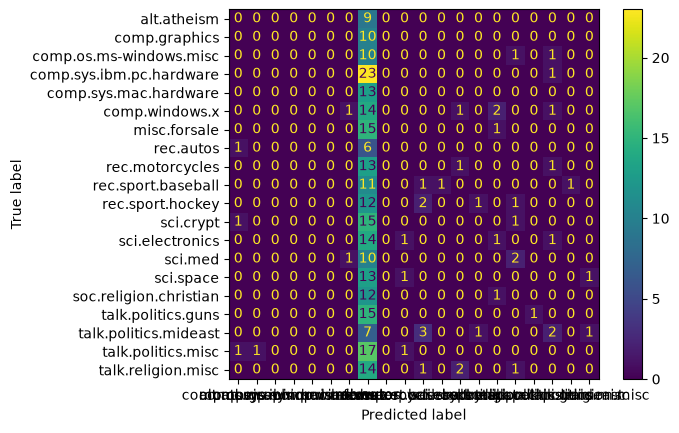

In [46]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

y_pred, y_true = predict(model, test_loader)
cm = confusion_matrix(y_true, y_pred)

ConfusionMatrixDisplay(cm, display_labels=class_names).plot()  # class_names optional
